In [7]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Load STRING PPI data
df = pd.read_csv(
    "4932.protein.links.v12.5.txt.gz",
    sep=r"\s+"
)

# Keep interactions with combined_score >= 750
df = df[df["combined_score"] >= 750].copy()

# Remove the STRING species prefix "4932."
df["protein1"] = df["protein1"].str.removeprefix("4932.")
df["protein2"] = df["protein2"].str.removeprefix("4932.")

# Construct an undirected, unweighted network
G_all = nx.from_pandas_edgelist(
    df,
    source="protein1",
    target="protein2"
)

# Remove self-loops, if any
G_all.remove_edges_from(nx.selfloop_edges(G_all))

print("Before LCC:")
print("Nodes:", G_all.number_of_nodes())
print("Edges:", G_all.number_of_edges())
print("Connected components:", nx.number_connected_components(G_all))

# Keep the largest connected component
largest_cc = max(nx.connected_components(G_all), key=len)
G = G_all.subgraph(largest_cc).copy()

print("\nAfter LCC:")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Connected:", nx.is_connected(G))

# Confirm HSC82 is present
print("HSC82 present:", "YMR186W" in G)

Before LCC:
Nodes: 5848
Edges: 105848
Connected components: 43

After LCC:
Nodes: 5747
Edges: 105784
Connected: True
HSC82 present: True


In [8]:
core_proteins = {
    "HSC82": "YMR186W",
    "SSA1": "YAL005C",
    "HSF1": "YGL073W"
}

In [9]:
print("Number of proteins:", G.number_of_nodes())
print("Number of interactions:", G.number_of_edges())
print("Network density:", round(nx.density(G), 5))
print("Average degree:", round(
    np.mean([degree for node, degree in G.degree()]), 2
))

for name, protein_id in core_proteins.items():
    print(name, protein_id, protein_id in G)

Number of proteins: 5747
Number of interactions: 105784
Network density: 0.00641
Average degree: 36.81
HSC82 YMR186W True
SSA1 YAL005C True
HSF1 YGL073W True


In [10]:
import igraph as ig
import leidenalg
from collections import Counter

# Convert NetworkX graph to igraph
nodes = list(G.nodes())
node_index = {node: i for i, node in enumerate(nodes)}

edges = [
    (node_index[u], node_index[v])
    for u, v in G.edges()
]

g_ig = ig.Graph(
    n=len(nodes),
    edges=edges,
    directed=False
)

# Leiden community detection
partition = leidenalg.find_partition(
    g_ig,
    leidenalg.RBConfigurationVertexPartition,
    weights=None,
    resolution_parameter=1.0,
    seed=42
)

# Convert communities back to protein IDs
communities = [
    {nodes[i] for i in community}
    for community in partition
]

# Map each protein to its community
node_to_community = {
    protein: cid
    for cid, community in enumerate(communities)
    for protein in community
}

# Community size distribution
community_sizes = pd.DataFrame({
    "Community": range(len(communities)),
    "Size": [len(c) for c in communities]
})

display(community_sizes)

print("Number of communities:", len(communities))
print("Total proteins:", sum(map(len, communities)))
print("HSC82 community:", node_to_community["YMR186W"])

,Community,Size
0,0,977
1,1,869
2,2,826
3,3,707
4,4,561
5,5,479
6,6,430
7,7,268
8,8,201
9,9,160


Number of communities: 21
Total proteins: 5747
HSC82 community: 2


In [11]:
# Load SGD gene annotations
sgd = pd.read_csv(
    "SGD_features.tab",
    sep="\t",
    header=None,
    dtype=str
)

# Extract relevant columns
sgd = sgd.iloc[:, [1, 2, 3, 4]].copy()

sgd.columns = [
    "feature_type",
    "qualifier",
    "systematic_name",
    "standard_name"
]

# Keep ORFs only
sgd = sgd[sgd["feature_type"] == "ORF"].copy()

# Create systematic -> standard name mapping
name_map = (
    sgd.drop_duplicates("systematic_name")
    .set_index("systematic_name")["standard_name"]
    .to_dict()
)

# Use systematic name when standard name is unavailable
protein_names = {
    node: name_map.get(node) or node
    for node in G.nodes()
}

# Check important proteins
for protein in ["YMR186W", "YAL005C", "YGL073W"]:
    print(protein, "->", protein_names[protein])

print("Mapped proteins:", len(protein_names))

YMR186W -> HSC82
YAL005C -> SSA1
YGL073W -> HSF1
Mapped proteins: 5747


In [12]:
protein_info = pd.DataFrame({
    "protein_id": list(G.nodes())
})

protein_info["protein"] = (
    protein_info["protein_id"].map(protein_names)
)

protein_info["community"] = (
    protein_info["protein_id"].map(node_to_community)
)

# Add dubious annotation
dubious_nodes = set(
    sgd.loc[
        sgd["qualifier"].str.contains(
            "Dubious", case=False, na=False
        ),
        "systematic_name"
    ]
)

protein_info["dubious"] = (
    protein_info["protein_id"].isin(dubious_nodes)
)

display(protein_info.head(10))

print("Total proteins:", len(protein_info))
print("Dubious proteins:", protein_info["dubious"].sum())
print("Communities:", protein_info["community"].nunique())

,protein_id,protein,community,dubious
0,Q0010,NaN,14,True
1,Q0017,NaN,14,True
2,Q0032,NaN,14,True
3,Q0092,NaN,14,True
4,Q0142,NaN,14,True
5,Q0143,NaN,14,True
6,Q0182,NaN,14,True
7,Q0297,NaN,14,True
8,Q0045,COX1,4,False
9,Q0050,AI1,4,False


Total proteins: 5747
Dubious proteins: 219
Communities: 21


In [13]:
import numpy as np
from scipy.sparse.linalg import eigsh

# 1. Degree centrality
degree = nx.degree_centrality(G)

# 2. Eigenvector centrality
eigenvector = nx.eigenvector_centrality(
    G, max_iter=2000, tol=1e-6
)

# 3. PageRank
pagerank = nx.pagerank(
    G, alpha=0.85, weight=None
)

# 4. Katz centrality
A = nx.to_scipy_sparse_array(
    G, weight=None, dtype=float
)

lambda_max = eigsh(
    A, k=1, which="LA",
    return_eigenvectors=False
)[0]

alpha_katz = 0.8 / lambda_max

katz = nx.katz_centrality(
    G,
    alpha=alpha_katz,
    beta=1.0,
    normalized=True,
    weight=None,
    max_iter=2000
)

print("Four centrality measures calculated.")
print("Katz alpha:", alpha_katz)

Four centrality measures calculated.
Katz alpha: 0.003915932296111737


In [14]:
centrality_df = protein_info.copy()

centrality_df["degree"] = centrality_df["protein_id"].map(degree)
centrality_df["eigenvector"] = centrality_df["protein_id"].map(eigenvector)
centrality_df["pagerank"] = centrality_df["protein_id"].map(pagerank)
centrality_df["katz"] = centrality_df["protein_id"].map(katz)

display(centrality_df.head())

print("Total proteins:", len(centrality_df))
print("Missing scores:",
      centrality_df[
          ["degree", "eigenvector", "pagerank", "katz"]
      ].isna().sum().sum())

,protein_id,protein,community,dubious,degree,eigenvector,pagerank,katz
0,Q0010,NaN,14,True,0.001218,2.109988e-07,0.000151,0.007621
1,Q0017,NaN,14,True,0.001218,2.109988e-07,0.000151,0.007621
2,Q0032,NaN,14,True,0.001218,2.109988e-07,0.000151,0.007621
3,Q0092,NaN,14,True,0.001740,4.181483e-05,0.000168,0.007746
4,Q0142,NaN,14,True,0.001218,2.109988e-07,0.000151,0.007621


Total proteins: 5747
Missing scores: 0


In [15]:
from scipy.sparse.linalg import eigsh

# Sparse adjacency matrix
nodes = list(G.nodes())

A = nx.to_scipy_sparse_array(
    G,
    nodelist=nodes,
    weight=None,
    dtype=float,
    format="csr"
)

# Leading eigenpairs
eigenvalues, eigenvectors = eigsh(
    A,
    k=100,
    which="LA"
)

# Approximate diagonal of exp(A)
subgraph_scores = (
    eigenvectors**2
) @ np.exp(eigenvalues - eigenvalues.max())

# Rescaled approximation (same rankings)
subgraph = dict(zip(nodes, subgraph_scores))

centrality_df["subgraph"] = (
    centrality_df["protein_id"].map(subgraph)
)

print("Approximate Subgraph Centrality calculated.")
display(
    centrality_df.nlargest(10, "subgraph")[
        ["protein", "community", "subgraph"]
    ]
)

Approximate Subgraph Centrality calculated.


,protein,community,subgraph
350,RPS13,5,0.006977
164,RPS3,5,0.006930
403,RPS5,5,0.006636
432,RPS1A,5,0.006627
337,RPS6B,5,0.006605
171,RPL25,5,0.006547
455,RPS7A,5,0.006408
332,RPS8A,5,0.006394
465,RPS9A,5,0.006377
106,RPS14A,5,0.006373


In [16]:
closeness = nx.closeness_centrality(
    G,
    distance=None
)

centrality_df["closeness"] = (
    centrality_df["protein_id"].map(closeness)
)

print("Closeness calculated.")
display(
    centrality_df.nlargest(10, "closeness")[
        ["protein", "community", "closeness"]
    ]
)

Closeness calculated.


,protein,community,closeness
295,PUF3,4,0.429158
364,RPN11,2,0.412136
655,ACT1,1,0.399055
517,DSN1,3,0.397097
100,HHT1,3,0.396057
164,RPS3,5,0.395676
133,RPS2,5,0.390406
99,HHF1,3,0.389032
440,ASC1,5,0.381515
556,HSP82,2,0.380656


In [17]:
# Approximate Betweenness Centrality
betweenness = nx.betweenness_centrality(
    G,
    k=500,
    normalized=True,
    weight=None,
    seed=42
)

centrality_df["betweenness"] = (
    centrality_df["protein_id"].map(betweenness)
)

print("Betweenness calculated.")
display(
    centrality_df.nlargest(10, "betweenness")[
        ["protein", "community", "betweenness"]
    ]
)

Betweenness calculated.


,protein,community,betweenness
295,PUF3,4,0.128325
364,RPN11,2,0.046146
655,ACT1,1,0.032263
517,DSN1,3,0.030064
100,HHT1,3,0.018727
485,CDC28,1,0.018167
99,HHF1,3,0.016177
1416,RSP5,7,0.014822
1879,UBI4,7,0.012990
340,PGK1,2,0.011856


In [18]:
measures = [
    "degree",
    "eigenvector",
    "katz",
    "pagerank",
    "betweenness",
    "subgraph",
    "closeness"
]

print(centrality_df[measures].isna().sum())
display(centrality_df[measures].head())

degree         0
eigenvector    0
katz           0
pagerank       0
betweenness    0
subgraph       0
closeness      0
dtype: int64


,degree,eigenvector,katz,pagerank,betweenness,subgraph,closeness
0,0.001218,2.109988e-07,0.007621,0.000151,0.000000,4.445050e-14,0.203147
1,0.001218,2.109988e-07,0.007621,0.000151,0.000000,4.445050e-14,0.203147
2,0.001218,2.109988e-07,0.007621,0.000151,0.000000,4.445050e-14,0.203147
3,0.001740,4.181483e-05,0.007746,0.000168,0.003214,1.747810e-09,0.254857
4,0.001218,2.109988e-07,0.007621,0.000151,0.000000,4.445050e-14,0.203147


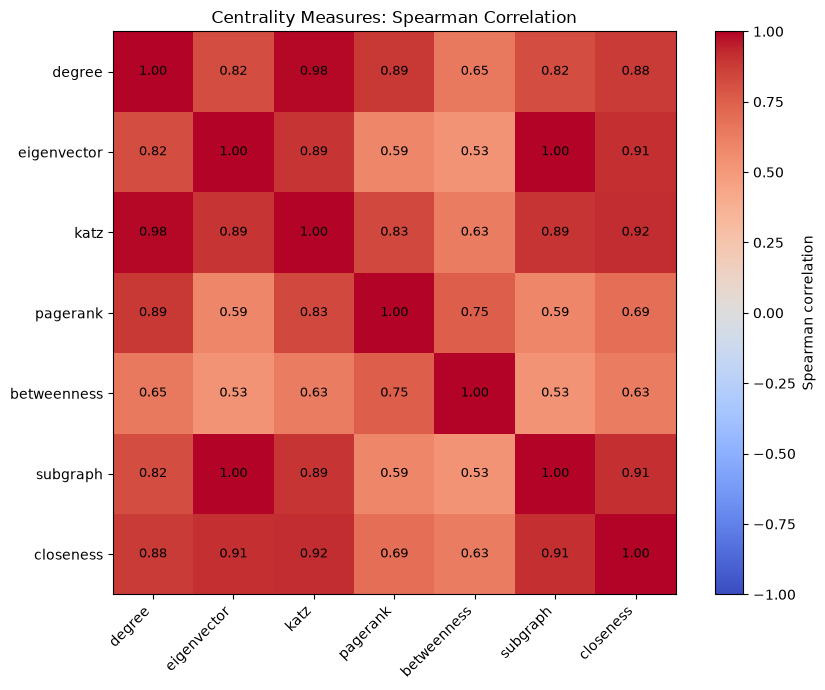

In [19]:
import matplotlib.pyplot as plt
import numpy as np

corr = centrality_df[measures].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(measures)))
ax.set_yticks(range(len(measures)))
ax.set_xticklabels(measures, rotation=45, ha="right")
ax.set_yticklabels(measures)

for i in range(len(measures)):
    for j in range(len(measures)):
        ax.text(
            j, i, f"{corr.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=9
        )

plt.colorbar(im, ax=ax, label="Spearman correlation")
plt.title("Centrality Measures: Spearman Correlation")
plt.tight_layout()
plt.show()

In [20]:
import pandas as pd
import numpy as np
import networkx as nx

# Match HSC82 ID to the current graph
HSC82 = (
    "4932.YMR186W"
    if "4932.YMR186W" in G
    else "YMR186W"
)

hsc82_cid = node_to_community[HSC82]
hsc82_nodes = communities[hsc82_cid]

# Shortest-path distances in the full connected network
distances = nx.single_source_shortest_path_length(G, HSC82)

rows = []

for cid, nodes in enumerate(communities):

    # Count dubious proteins
    dubious_count = len(nodes & dubious_nodes)

    # Count edges between this community and HSC82 community
    if cid == hsc82_cid:
        edges_to_hsc82 = 0
    else:
        edges_to_hsc82 = sum(
            1
            for u, v in G.edges()
            if (
                (u in nodes and v in hsc82_nodes)
                or (v in nodes and u in hsc82_nodes)
            )
        )

    # Distances from HSC82
    d = [distances[node] for node in nodes]

    rows.append({
        "Community": cid,
        "Size": len(nodes),
        "Dubious_count": dubious_count,
        "Dubious_%": 100 * dubious_count / len(nodes),
        "Edges_to_HSC82": edges_to_hsc82,
        "Mean_distance_HSC82": np.mean(d),
        "Distance_>=5_%": 100 * sum(x >= 5 for x in d) / len(d)
    })

community_summary = pd.DataFrame(rows)

display(
    community_summary.round(2)
    .sort_values("Community")
    .reset_index(drop=True)
)

print("HSC82 community:", hsc82_cid)
print("Total communities:", len(community_summary))

,Community,Size,Dubious_count,Dubious_%,Edges_to_HSC82,Mean_distance_HSC82,Distance_>=5_%
0,0,977,21,2.15,646,2.77,1.74
1,1,869,11,1.27,748,2.48,1.27
2,2,826,11,1.33,0,2.62,1.33
3,3,707,7,0.99,602,2.29,0.00
4,4,561,9,1.60,735,2.80,2.67
5,5,479,2,0.42,916,2.13,0.00
6,6,430,19,4.42,238,2.76,3.02
7,7,268,7,2.61,315,2.56,1.49
8,8,201,66,32.84,13,4.83,62.69
9,9,160,3,1.88,135,2.94,8.12


HSC82 community: 2
Total communities: 21


In [21]:
import pandas as pd
import numpy as np
import networkx as nx
import igraph as ig
import leidenalg
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

# ==========================
# Parameters
# ==========================

FILE = "4932.protein.links.v12.5.txt.gz"

THRESHOLD = 750
RESOLUTION = 1.0
MIN_SIZE = 2
N_RUNS = 10
TOP_N = 10

SEEDS = list(range(N_RUNS))

HSC82 = "4932.YMR186W"
SSA1 = "4932.YAL005C"
HSF1 = "4932.YGL073W"

OUTPUT = Path("community_results")
OUTPUT.mkdir(exist_ok=True)

In [22]:
# Load STRING data
df = pd.read_csv(FILE, sep=r"\s+")

# Filter high-confidence interactions
df = df[df["combined_score"] >= THRESHOLD].copy()

# Construct unweighted, undirected graph
G_all = nx.from_pandas_edgelist(
    df,
    source="protein1",
    target="protein2"
)

G_all.remove_edges_from(nx.selfloop_edges(G_all))

# Largest connected component
largest_cc = max(nx.connected_components(G_all), key=len)
G = G_all.subgraph(largest_cc).copy()

print("Filtered PPI network:")
print("Nodes:", G_all.number_of_nodes())
print("Edges:", G_all.number_of_edges())

print("\nLargest connected component:")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

# Check reference proteins
for name, protein in {
    "HSC82": HSC82,
    "SSA1": SSA1,
    "HSF1": HSF1
}.items():
    print(name, "in network:", protein in G)

assert HSC82 in G

Filtered PPI network:
Nodes: 5848
Edges: 105848

Largest connected component:
Nodes: 5747
Edges: 105784
HSC82 in network: True
SSA1 in network: True
HSF1 in network: True


In [23]:
# Convert NetworkX graph to igraph for Leiden
g = ig.Graph.from_networkx(G)

def run_detection(method, seed):

    if method == "Louvain":

        communities = nx.community.louvain_communities(
            G,
            weight=None,
            resolution=RESOLUTION,
            seed=seed
        )

        return [set(c) for c in communities]

    elif method == "Leiden":

        partition = leidenalg.find_partition(
            g,
            leidenalg.RBConfigurationVertexPartition,
            weights=None,
            resolution_parameter=RESOLUTION,
            seed=seed
        )

        communities = [
            {g.vs[i]["_nx_name"] for i in c}
            for c in partition
        ]

        return communities

    else:
        raise ValueError("Unknown community detection method")

In [24]:
all_partitions = {
    "Louvain": {},
    "Leiden": {}
}

results = []

for method in ["Louvain", "Leiden"]:

    print(f"\nRunning {method}...")

    for seed in SEEDS:

        communities = run_detection(method, seed)

        # Verify partition
        assert set().union(*communities) == set(G.nodes())
        assert sum(len(c) for c in communities) == G.number_of_nodes()

        all_partitions[method][seed] = communities

        sizes = sorted(
            [len(c) for c in communities],
            reverse=True
        )

        hsc82_comm = next(
            c for c in communities if HSC82 in c
        )

        modularity = nx.community.modularity(
            G,
            communities,
            weight=None
        )

        results.append({
            "Method": method,
            "Seed": seed,
            "Number of communities": len(communities),
            "Minimum size": min(sizes),
            "Median size": np.median(sizes),
            "Mean size": np.mean(sizes),
            "Maximum size": max(sizes),
            "HSC82 community size": len(hsc82_comm),
            "Modularity": modularity
        })

        print(
            f"Seed {seed}: "
            f"{len(communities)} communities, "
            f"Q = {modularity:.4f}"
        )

results_df = pd.DataFrame(results)

display(results_df)


Running Louvain...
Seed 0: 22 communities, Q = 0.6082
Seed 1: 21 communities, Q = 0.6091
Seed 2: 20 communities, Q = 0.6111
Seed 3: 18 communities, Q = 0.5987
Seed 4: 20 communities, Q = 0.6102
Seed 5: 21 communities, Q = 0.6075
Seed 6: 21 communities, Q = 0.6097
Seed 7: 20 communities, Q = 0.6077
Seed 8: 20 communities, Q = 0.6099
Seed 9: 20 communities, Q = 0.6098

Running Leiden...
Seed 0: 20 communities, Q = 0.6122
Seed 1: 17 communities, Q = 0.6118
Seed 2: 23 communities, Q = 0.6112
Seed 3: 22 communities, Q = 0.6149
Seed 4: 21 communities, Q = 0.6117
Seed 5: 19 communities, Q = 0.6116
Seed 6: 21 communities, Q = 0.6133
Seed 7: 19 communities, Q = 0.6093
Seed 8: 19 communities, Q = 0.6119
Seed 9: 17 communities, Q = 0.6154


,Method,Seed,Number of communities,Minimum size,Median size,Mean size,Maximum size,HSC82 community size,Modularity
0,Louvain,0,22,4,172.5,261.227273,1048,533,0.608249
1,Louvain,1,21,4,199.0,273.666667,958,505,0.609138
2,Louvain,2,20,4,218.5,287.350000,1109,512,0.611127
3,Louvain,3,18,4,215.0,319.277778,1071,501,0.598674
4,Louvain,4,20,4,193.0,287.350000,1122,603,0.610202
5,Louvain,5,21,4,194.0,273.666667,895,534,0.607539
6,Louvain,6,21,2,105.0,273.666667,1397,509,0.609726
7,Louvain,7,20,4,183.5,287.350000,1112,852,0.607650
8,Louvain,8,20,3,213.0,287.350000,1160,515,0.609881
9,Louvain,9,20,2,209.5,287.350000,1095,506,0.609782


In [25]:
summary = (
    results_df
    .groupby("Method")
    .agg({
        "Number of communities": ["mean", "std", "min", "max"],
        "Minimum size": ["mean", "min"],
        "Median size": ["mean", "std"],
        "Maximum size": ["mean", "std"],
        "HSC82 community size": ["mean", "std"],
        "Modularity": ["mean", "std"]
    })
)

display(summary.round(3))

Number of communities                Minimum size     Median size  \
                         mean    std min max         mean min        mean   
Method                                                                      
Leiden                   19.8  1.989  17  23          3.2   2       193.3   
Louvain                  20.3  1.059  18  22          3.5   2       190.3   

                Maximum size          HSC82 community size           \
            std         mean      std                 mean      std   
Method                                                                
Leiden   59.560       1059.6  205.614                492.0  144.892   
Louvain  33.375       1096.7  132.568                557.0  107.899   

        Modularity         
              mean    std  
Method                     
Leiden       0.612  0.002  
Louvain      0.608  0.004

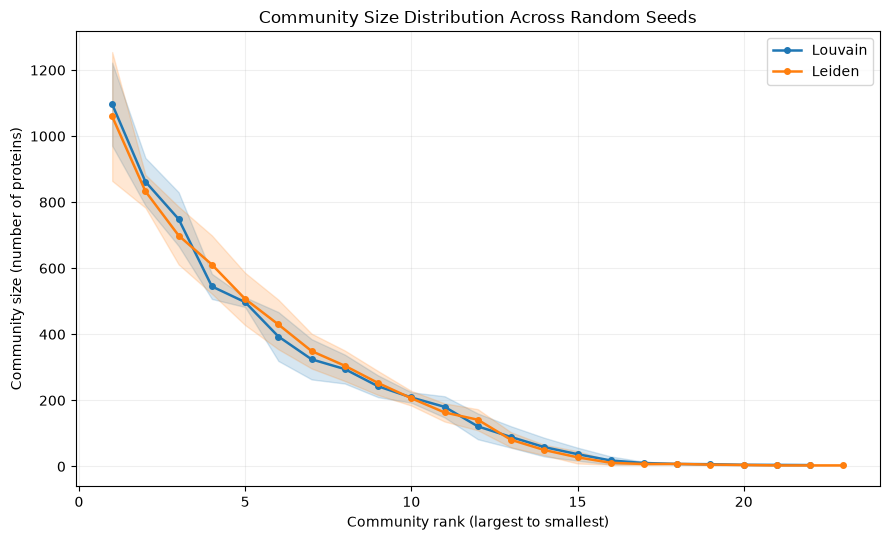

In [26]:
fig, ax = plt.subplots(figsize=(9, 5.5))

for method in ["Louvain", "Leiden"]:

    size_lists = [
        sorted(
            [len(c) for c in all_partitions[method][seed]],
            reverse=True
        )
        for seed in SEEDS
    ]

    max_len = max(len(s) for s in size_lists)

    matrix = np.full(
        (N_RUNS, max_len),
        np.nan
    )

    for i, sizes in enumerate(size_lists):
        matrix[i, :len(sizes)] = sizes

    mean_sizes = np.nanmean(matrix, axis=0)
    std_sizes = np.nanstd(matrix, axis=0)

    ranks = np.arange(1, max_len + 1)

    line, = ax.plot(
        ranks,
        mean_sizes,
        marker="o",
        markersize=4,
        linewidth=1.8,
        label=method
    )

    ax.fill_between(
        ranks,
        np.maximum(mean_sizes - std_sizes, 0),
        mean_sizes + std_sizes,
        color=line.get_color(),
        alpha=0.18
    )

ax.set_xlabel("Community rank (largest to smallest)")
ax.set_ylabel("Community size (number of proteins)")
ax.set_title("Community Size Distribution Across Random Seeds")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    OUTPUT / "community_size_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

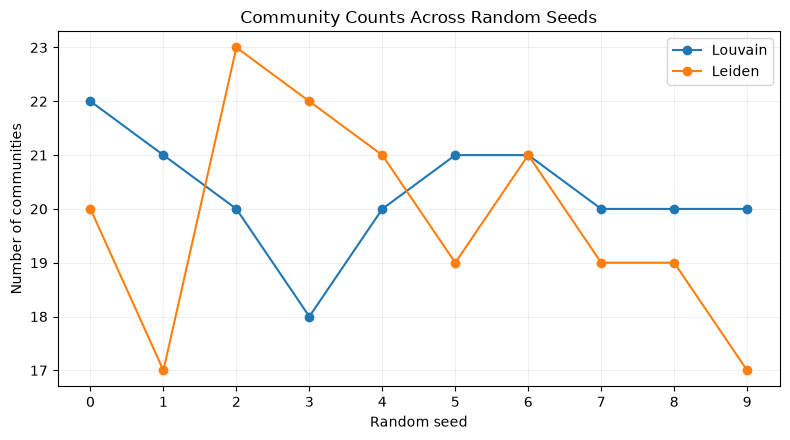

In [27]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for method in ["Louvain", "Leiden"]:

    data = results_df[
        results_df["Method"] == method
    ]

    ax.plot(
        data["Seed"],
        data["Number of communities"],
        marker="o",
        linewidth=1.5,
        label=method
    )

ax.set_xlabel("Random seed")
ax.set_ylabel("Number of communities")
ax.set_title("Community Counts Across Random Seeds")

ax.set_xticks(SEEDS)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    OUTPUT / "community_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
import pandas as pd
import networkx as nx

df = pd.read_csv(
    "4932.protein.links.v12.5.txt.gz",
    sep=r"\s+"
)

df = df[df["combined_score"] >= 750]

G_all = nx.from_pandas_edgelist(
    df,
    source="protein1",
    target="protein2",
    edge_attr="combined_score"
)

# Keep largest connected component
largest_cc = max(nx.connected_components(G_all), key=len)
G = G_all.subgraph(largest_cc).copy()

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 5747
Edges: 105784


In [29]:
import igraph as ig
import leidenalg
import networkx as nx

SEED = 42
HSC82 = "4932.YMR186W"
MIN_SIZE = 2

# Louvain
louvain_communities = [
    set(c) for c in nx.community.louvain_communities(
        G,
        weight=None,
        resolution=1.0,
        seed=SEED
    )
]

# Leiden
g = ig.Graph.from_networkx(G)

partition = leidenalg.find_partition(
    g,
    leidenalg.RBConfigurationVertexPartition,
    weights=None,
    resolution_parameter=1.0,
    seed=SEED
)

leiden_communities = [
    {g.vs[i]["_nx_name"] for i in c}
    for c in partition
]

partitions = {
    "Louvain": louvain_communities,
    "Leiden": leiden_communities
}

for method, comms in partitions.items():
    print(method, ":", len(comms), "communities")

Louvain : 21 communities
Leiden : 21 communities


In [30]:
hsc82_info = {}

for method, comms in partitions.items():

    for cid, community in enumerate(comms):
        if HSC82 in community:

            hsc82_info[method] = {
                "community_id": cid,
                "proteins": community,
                "size": len(community)
            }

            print(
                method,
                "| HSC82 community:", cid,
                "| Size:", len(community)
            )
            break

Louvain | HSC82 community: 17 | Size: 505
Leiden | HSC82 community: 2 | Size: 826


In [31]:
from collections import Counter
import pandas as pd

adjacent_results = {}

for method, comms in partitions.items():

    hsc82_cid = hsc82_info[method]["community_id"]

    node_to_community = {
        node: cid
        for cid, community in enumerate(comms)
        for node in community
    }

    adjacent_counts = Counter()

    for u, v in G.edges():
        cu = node_to_community[u]
        cv = node_to_community[v]

        if cu == hsc82_cid and cv != hsc82_cid:
            adjacent_counts[cv] += 1

        elif cv == hsc82_cid and cu != hsc82_cid:
            adjacent_counts[cu] += 1

    adjacent_df = pd.DataFrame([
        {
            "Community": cid,
            "Size": len(comms[cid]),
            "Edges to HSC82 community": count
        }
        for cid, count in adjacent_counts.items()
        if len(comms[cid]) >= MIN_SIZE
    ])

    adjacent_results[method] = adjacent_df

    print(f"\n{method}")
    print("Adjacent communities:", len(adjacent_df))
    display(adjacent_df)


Louvain
Adjacent communities: 15


,Community,Size,Edges to HSC82 community
0,0,8,1
1,1,212,370
2,12,307,511
3,13,313,142
4,10,780,282
5,6,979,419
6,11,767,629
7,3,994,375
8,7,82,18
9,15,154,99



Leiden
Adjacent communities: 15


,Community,Size,Edges to HSC82 community
0,4,561,735
1,5,479,916
2,3,707,602
3,0,977,646
4,6,430,238
5,10,144,102
6,1,869,748
7,9,160,135
8,7,268,315
9,12,24,9


In [32]:
density_results = {}

for method, adjacent_df in adjacent_results.items():

    df_density = adjacent_df.copy()

    hsc82_size = hsc82_info[method]["size"]

    df_density["Edge density"] = (
        df_density["Edges to HSC82 community"]
        / (hsc82_size * df_density["Size"])
    )

    df_density = df_density.sort_values(
        ["Edge density", "Edges to HSC82 community", "Community"],
        ascending=[False, False, True]
    ).reset_index(drop=True)

    density_results[method] = df_density

    print(f"\n{method} — Ranked by edge density")
    display(df_density)


Louvain — Ranked by edge density


,Community,Size,Edges to HSC82 community,Edge density
0,1,212,370,0.003456
1,12,307,511,0.003296
2,11,767,629,0.001624
3,15,154,99,0.001273
4,13,313,142,0.000898
5,6,979,419,0.000848
6,3,994,375,0.000747
7,10,780,282,0.000716
8,9,198,71,0.000710
9,5,104,23,0.000438



Leiden — Ranked by edge density


,Community,Size,Edges to HSC82 community,Edge density
0,5,479,916,0.002315
1,4,561,735,0.001586
2,7,268,315,0.001423
3,1,869,748,0.001042
4,3,707,602,0.001031
5,9,160,135,0.001021
6,10,144,102,0.000858
7,0,977,646,0.000800
8,6,430,238,0.000670
9,12,24,9,0.000454


In [33]:
TOP_N = 10

top10_results = {}
selected_community_ids = {}
selected_communities = {}

for method, df_density in density_results.items():

    top10 = df_density.head(TOP_N).copy()

    top10.insert(
        0, "Rank", range(1, len(top10) + 1)
    )

    top10_results[method] = top10

    ids = top10["Community"].tolist()

    selected_community_ids[method] = ids

    selected_communities[method] = {
        cid: partitions[method][cid]
        for cid in ids
    }

    print(f"\n{method} — Top 10 adjacent communities")
    display(top10)

    print("Community IDs:", ids)
    print(
        "Total proteins:",
        sum(len(c) for c in selected_communities[method].values())
    )


Louvain — Top 10 adjacent communities


,Rank,Community,Size,Edges to HSC82 community,Edge density
0,1,1,212,370,0.003456
1,2,12,307,511,0.003296
2,3,11,767,629,0.001624
3,4,15,154,99,0.001273
4,5,13,313,142,0.000898
5,6,6,979,419,0.000848
6,7,3,994,375,0.000747
7,8,10,780,282,0.000716
8,9,9,198,71,0.000710
9,10,5,104,23,0.000438


Community IDs: [1, 12, 11, 15, 13, 6, 3, 10, 9, 5]
Total proteins: 4808

Leiden — Top 10 adjacent communities


,Rank,Community,Size,Edges to HSC82 community,Edge density
0,1,5,479,916,0.002315
1,2,4,561,735,0.001586
2,3,7,268,315,0.001423
3,4,1,869,748,0.001042
4,5,3,707,602,0.001031
5,6,9,160,135,0.001021
6,7,10,144,102,0.000858
7,8,0,977,646,0.000800
8,9,6,430,238,0.000670
9,10,12,24,9,0.000454


Community IDs: [5, 4, 7, 1, 3, 9, 10, 0, 6, 12]
Total proteins: 4619


In [34]:
for method in ["Louvain", "Leiden"]:

    top10_results[method].to_csv(
        f"{method.lower()}_top10_communities.csv",
        index=False
    )

    rows = []

    for cid, proteins in selected_communities[method].items():
        for protein in sorted(proteins):
            rows.append({
                "Method": method,
                "Seed": SEED,
                "Community": cid,
                "Protein": protein
            })

    pd.DataFrame(rows).to_csv(
        f"{method.lower()}_top10_proteins.csv",
        index=False
    )

In [53]:
import pandas as pd
import networkx as nx

MEASURES = ["betweenness", "pagerank", "eigenvector"]
TOP_K = 3

# Calculate shortest-path distances on the FULL network
dist_hsc82 = nx.single_source_shortest_path_length(G, HSC82)

centrality_results = []
top3_results = []

for method in ["Louvain", "Leiden"]:

    communities = partitions[method]
    selected_ids = selected_community_ids[method]

    for cid in selected_ids:

        # Extract the full community subgraph
        subG = G.subgraph(communities[cid]).copy()
        n = subG.number_of_nodes()

        # 1. Betweenness
        if n > 300:
            betweenness = nx.betweenness_centrality(
                subG,
                k=min(100, n),
                seed=42,
                weight=None
            )
        else:
            betweenness = nx.betweenness_centrality(
                subG,
                weight=None
            )

        # 2. PageRank
        pagerank = nx.pagerank(
            subG,
            alpha=0.85,
            weight=None
        )

        # 3. Eigenvector
        eigenvector = nx.eigenvector_centrality(
            subG,
            max_iter=3000,
            tol=1e-6,
            weight=None
        )

        scores = {
            "betweenness": betweenness,
            "pagerank": pagerank,
            "eigenvector": eigenvector
        }

        # Store all centrality scores
        for protein in subG.nodes():

            row = {
                "Algorithm": method,
                "Community": cid,
                "Community size": n,
                "Protein": protein,
                "Distance to HSC82": dist_hsc82[protein]
            }

            for measure in MEASURES:
                row[measure] = scores[measure][protein]

            centrality_results.append(row)

        
        # Select proteins without distance restriction
        eligible_proteins = list(subG.nodes())
            
        # Select Top 3 eligible proteins for each measure
        for measure in MEASURES:

            ranked = sorted(
                eligible_proteins,
                key=lambda protein: (
                    -scores[measure][protein],
                    protein
                )
            )

            for rank, protein in enumerate(
                ranked[:TOP_K], start=1
            ):

                top3_results.append({
                    "Algorithm": method,
                    "Community": cid,
                    "Community size": n,
                    "Measure": measure,
                    "Rank": rank,
                    "Protein": protein,
                    "Distance to HSC82": dist_hsc82[protein],
                    "Score": scores[measure][protein]
                })

centrality_df = pd.DataFrame(centrality_results)
top3_df = pd.DataFrame(top3_results)

display(top3_df)

print("Total selections:", len(top3_df))

print("\nUnique proteins by algorithm:")
print(top3_df.groupby("Algorithm")["Protein"].nunique())

,Algorithm,Community,Community size,Measure,Rank,Protein,Distance to HSC82,Score
0,Louvain,1,212,betweenness,1,4932.YLL013C,2,0.553135
1,Louvain,1,212,betweenness,2,4932.YCR046C,2,0.071028
2,Louvain,1,212,betweenness,3,4932.YCR051W,3,0.055744
3,Louvain,1,212,pagerank,1,4932.YLL013C,2,0.036917
4,Louvain,1,212,pagerank,2,4932.YBR251W,2,0.009955
...,...,...,...,...,...,...,...,...
175,Leiden,12,24,pagerank,2,4932.YIL064W,2,0.065625
176,Leiden,12,24,pagerank,3,4932.YLR137W,2,0.056553
177,Leiden,12,24,eigenvector,1,4932.YBR271W,2,0.372803
178,Leiden,12,24,eigenvector,2,4932.YIL064W,2,0.357048


Total selections: 180

Unique proteins by algorithm:
Algorithm
Leiden     66
Louvain    64
Name: Protein, dtype: int64


In [54]:
import pandas as pd
import networkx as nx

# Distance from HSC82 in the full network
dist_hsc82 = nx.single_source_shortest_path_length(
    G, HSC82
)

# Load SGD annotations
# Change filename to your actual SGD file
sgd = pd.read_csv("SGD_features.tab", sep="\t", header=None)

# SGD_features.tab:
# column 3 = Feature Name (standard name)
# column 4 = Gene Name
# column 5 = Alias
# column 1 = Feature Type
# column 2 = Feature Qualifier

# For reliable mapping, use the systematic name from column 3
# after checking your file's column layout.
display(sgd.head())

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,S000350094,ORF,Verified,YDL204W-A,NaN,NaN,chromosome 4,NaN,4,94133,94285,W,NaN,2024-05-28,2024-05-28,"Protein of unknown function, translated but no..."
1,S000350094,CDS,NaN,NaN,NaN,NaN,YDL204W-A,NaN,4,94133,94285,W,NaN,2024-05-28,2024-05-28,NaN
2,S000350095,ORF,Verified,YFR035W-A,NaN,NaN,chromosome 6,NaN,6,226260,226550,W,NaN,2024-05-28,2024-05-28,Protein of unknown function; added to genome a...
3,S000350095,CDS,NaN,NaN,NaN,NaN,YFR035W-A,NaN,6,226260,226550,W,NaN,2024-05-28,2024-05-28,NaN
4,S000001326,ORF,Verified,YIL064W,EFM4,SEE1,chromosome 9,NaN,9,242027,242716,W,NaN,2024-05-28,2024-05-28,Lysine methyltransferase; involved in the dime...


In [55]:
top3_annotated = top3_df.copy()

top3_annotated["Systematic name"] = (
    top3_annotated["Protein"].str.replace(
        "4932.", "", regex=False
    )
)

top3_annotated["Standard name"] = (
    top3_annotated["Systematic name"].map(name_map)
)

top3_annotated["Dubious"] = (
    top3_annotated["Systematic name"].isin(dubious_nodes)
)

display(top3_annotated)

,Algorithm,Community,Community size,Measure,Rank,Protein,Distance to HSC82,Score,Systematic name,Standard name,Dubious
0,Louvain,1,212,betweenness,1,4932.YLL013C,2,0.553135,YLL013C,PUF3,False
1,Louvain,1,212,betweenness,2,4932.YCR046C,2,0.071028,YCR046C,IMG1,False
2,Louvain,1,212,betweenness,3,4932.YCR051W,3,0.055744,YCR051W,ACL1,False
3,Louvain,1,212,pagerank,1,4932.YLL013C,2,0.036917,YLL013C,PUF3,False
4,Louvain,1,212,pagerank,2,4932.YBR251W,2,0.009955,YBR251W,MRPS5,False
...,...,...,...,...,...,...,...,...,...,...,...
175,Leiden,12,24,pagerank,2,4932.YIL064W,2,0.065625,YIL064W,EFM4,False
176,Leiden,12,24,pagerank,3,4932.YLR137W,2,0.056553,YLR137W,RKM5,False
177,Leiden,12,24,eigenvector,1,4932.YBR271W,2,0.372803,YBR271W,EFM2,False
178,Leiden,12,24,eigenvector,2,4932.YIL064W,2,0.357048,YIL064W,EFM4,False


In [56]:
overlap_df = (
    top3_annotated
    .groupby([
        "Algorithm",
        "Community",
        "Protein",
        "Systematic name",
        "Standard name",
        "Distance to HSC82",
        "Dubious"
    ], dropna=False)
    .agg(
        Measures=("Measure", lambda x: ", ".join(sorted(set(x)))),
        Number_of_measures=("Measure", "nunique")
    )
    .reset_index()
    .sort_values(
        ["Algorithm", "Community", "Number_of_measures"],
        ascending=[True, True, False]
    )
)

display(overlap_df)

print("\nProteins selected by multiple centrality measures:")

display(
    overlap_df[
        overlap_df["Number_of_measures"] >= 2
    ]
)

,Algorithm,Community,Protein,Systematic name,Standard name,Distance to HSC82,Dubious,Measures,Number_of_measures
0,Leiden,0,4932.YFL038C,YFL038C,YPT1,2,False,pagerank,1
1,Leiden,0,4932.YGL206C,YGL206C,CHC1,2,False,betweenness,1
2,Leiden,0,4932.YJL034W,YJL034W,KAR2,1,False,pagerank,1
3,Leiden,0,4932.YKL196C,YKL196C,YKT6,3,False,eigenvector,1
4,Leiden,0,4932.YLR026C,YLR026C,SED5,3,False,eigenvector,1
...,...,...,...,...,...,...,...,...,...
125,Louvain,15,4932.YGL048C,YGL048C,RPT6,2,False,eigenvector,1
126,Louvain,15,4932.YHR027C,YHR027C,RPN1,1,False,pagerank,1
127,Louvain,15,4932.YIL089W,YIL089W,NaN,4,False,betweenness,1
128,Louvain,15,4932.YKL145W,YKL145W,RPT1,2,False,eigenvector,1



Proteins selected by multiple centrality measures:


,Algorithm,Community,Protein,Systematic name,Standard name,Distance to HSC82,Dubious,Measures,Number_of_measures
9,Leiden,1,4932.YBR160W,YBR160W,CDC28,1,False,"betweenness, eigenvector, pagerank",3
10,Leiden,1,4932.YDR477W,YDR477W,SNF1,2,False,"betweenness, pagerank",2
11,Leiden,1,4932.YFL039C,YFL039C,ACT1,1,False,"betweenness, pagerank",2
14,Leiden,3,4932.YBR009C,YBR009C,HHF1,2,False,"betweenness, eigenvector, pagerank",3
15,Leiden,3,4932.YBR010W,YBR010W,HHT1,2,False,"betweenness, eigenvector, pagerank",3
17,Leiden,3,4932.YDR224C,YDR224C,HTB1,2,False,"betweenness, pagerank",2
22,Leiden,4,4932.YKR016W,YKR016W,MIC60,2,False,"betweenness, pagerank",2
23,Leiden,4,4932.YLL013C,YLL013C,PUF3,2,False,"betweenness, pagerank",2
26,Leiden,5,4932.YDR064W,YDR064W,RPS13,2,False,"betweenness, eigenvector, pagerank",3
25,Leiden,5,4932.YBR181C,YBR181C,RPS6B,2,False,"eigenvector, pagerank",2


In [57]:
louvain_set = set(
    top3_annotated.loc[
        top3_annotated["Algorithm"] == "Louvain",
        "Protein"
    ]
)

leiden_set = set(
    top3_annotated.loc[
        top3_annotated["Algorithm"] == "Leiden",
        "Protein"
    ]
)

common = louvain_set & leiden_set
only_louvain = louvain_set - leiden_set
only_leiden = leiden_set - louvain_set

jaccard = len(common) / len(louvain_set | leiden_set)

print("Louvain unique proteins:", len(louvain_set))
print("Leiden unique proteins:", len(leiden_set))
print("Common proteins:", len(common))
print("Only Louvain:", len(only_louvain))
print("Only Leiden:", len(only_leiden))
print("Jaccard similarity:", round(jaccard, 4))

# Show shared proteins with annotations
shared_df = (
    top3_annotated[
        top3_annotated["Protein"].isin(common)
    ]
    .drop_duplicates(subset=["Protein"])
    [[
        "Protein",
        "Systematic name",
        "Standard name",
        "Distance to HSC82",
        "Dubious"
    ]]
    .sort_values("Distance to HSC82")
    .reset_index(drop=True)
)

display(shared_df)

Louvain unique proteins: 64
Leiden unique proteins: 66
Common proteins: 30
Only Louvain: 34
Only Leiden: 36
Jaccard similarity: 0.3


,Protein,Systematic name,Standard name,Distance to HSC82,Dubious
0,4932.YLL039C,YLL039C,UBI4,1,False
1,4932.YOR117W,YOR117W,RPT5,1,False
2,4932.YJL034W,YJL034W,KAR2,1,False
3,4932.YFL039C,YFL039C,ACT1,1,False
4,4932.YBR160W,YBR160W,CDC28,1,False
5,4932.YNR036C,YNR036C,MRPS12,2,False
6,4932.YPL013C,YPL013C,MRPS16,2,False
7,4932.YLL013C,YLL013C,PUF3,2,False
8,4932.YBL041W,YBL041W,PRE7,2,False
9,4932.YNL178W,YNL178W,RPS3,2,False


In [58]:
from collections import Counter
import pandas as pd
import numpy as np
import networkx as nx

robust_rows = []

for method in ["Louvain", "Leiden"]:
    for seed in SEEDS:

        comms = all_partitions[method][seed]

        # Find HSC82 community
        hcid = next(i for i, c in enumerate(comms) if HSC82 in c)
        hsize = len(comms[hcid])

        lookup = {
            protein: i
            for i, community in enumerate(comms)
            for protein in community
        }

        # Find adjacent communities
        counts = Counter()

        for u, v in G.edges():
            cu, cv = lookup[u], lookup[v]

            if cu == hcid and cv != hcid:
                counts[cv] += 1
            elif cv == hcid and cu != hcid:
                counts[cu] += 1

        adjacent = pd.DataFrame([
            {
                "Community": cid,
                "Size": len(comms[cid]),
                "Edges": count,
                "Density": count / (hsize * len(comms[cid]))
            }
            for cid, count in counts.items()
            if len(comms[cid]) >= MIN_SIZE
        ])

        if adjacent.empty:
            continue

        selected = (
            adjacent.sort_values("Density", ascending=False)
            .head(TOP_N)
        )

        # Repeat centrality selection
        for cid in selected["Community"]:

            subG = G.subgraph(comms[cid]).copy()

            scores = {
                "betweenness": nx.betweenness_centrality(subG),
                "pagerank": nx.pagerank(subG),
                "eigenvector": nx.eigenvector_centrality(
                    subG, max_iter=3000
                )
            }

            for measure in MEASURES:

                ranked = sorted(
                    subG.nodes(),
                    key=lambda p: scores[measure][p],
                    reverse=True
                )

                for protein in ranked[:TOP_K]:
                    robust_rows.append({
                        "Algorithm": method,
                        "Seed": seed,
                        "Protein": protein,
                        "Measure": measure
                    })

robust_df = pd.DataFrame(robust_rows)

In [59]:
protein_frequency = (
    robust_df[["Algorithm", "Seed", "Protein"]]
    .drop_duplicates()
    .groupby(["Algorithm", "Protein"])["Seed"]
    .nunique()
    .reset_index(name="Count")
)

protein_frequency["Frequency"] = (
    protein_frequency["Count"] / len(SEEDS)
)

display(
    protein_frequency.sort_values(
        ["Algorithm", "Count"],
        ascending=[True, False]
    )
)

,Algorithm,Protein,Count,Frequency
3,Leiden,4932.YAL038W,10,1.0
7,Leiden,4932.YBR009C,10,1.0
8,Leiden,4932.YBR010W,10,1.0
9,Leiden,4932.YBR088C,10,1.0
12,Leiden,4932.YBR160W,10,1.0
...,...,...,...,...
296,Louvain,4932.YOL114C,1,0.1
301,Louvain,4932.YOR065W,1,0.1
303,Louvain,4932.YOR096W,1,0.1
307,Louvain,4932.YOR175C,1,0.1


In [61]:
# Reference proteins selected using seed 42
reference = top3_df[
    ["Algorithm", "Protein"]
].drop_duplicates()

# Match reference proteins with robustness results
robustness_check = reference.merge(
    protein_frequency,
    on=["Algorithm", "Protein"],
    how="left"
)

robustness_check["Count"] = (
    robustness_check["Count"].fillna(0).astype(int)
)

robustness_check["Frequency"] = (
    robustness_check["Frequency"].fillna(0)
)

# Filter proteins selected in at least 8 out of 10 seeds
FREQ_THRESHOLD = 0.8

stable_proteins = (
    robustness_check[
        robustness_check["Frequency"] >= FREQ_THRESHOLD
    ]
    .sort_values(
        ["Algorithm", "Frequency"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(stable_proteins)

print("\nNumber of stable proteins:")
print(stable_proteins.groupby("Algorithm")["Protein"].nunique())

stable_proteins.to_csv("stable_proteins.csv", index=False)

,Algorithm,Protein,Count,Frequency
0,Leiden,4932.YNL178W,10,1.0
1,Leiden,4932.YBR160W,10,1.0
2,Leiden,4932.YFL039C,10,1.0
3,Leiden,4932.YDR477W,10,1.0
4,Leiden,4932.YBR010W,10,1.0
5,Leiden,4932.YBR009C,10,1.0
6,Leiden,4932.YBR088C,10,1.0
7,Leiden,4932.YBR251W,10,1.0
8,Leiden,4932.YPL013C,10,1.0
9,Leiden,4932.YNR036C,10,1.0



Number of stable proteins:
Algorithm
Leiden     19
Louvain    37
Name: Protein, dtype: int64


In [62]:
# Add standard names to stable proteins

stable_proteins["Systematic name"] = (
    stable_proteins["Protein"]
    .str.replace("4932.", "", regex=False)
)

stable_proteins["Standard name"] = (
    stable_proteins["Systematic name"]
    .map(name_map)
)

# Reorder columns
stable_proteins = stable_proteins[
    [
        "Algorithm",
        "Protein",
        "Systematic name",
        "Standard name",
        "Count",
        "Frequency"
    ]
]

display(stable_proteins)

stable_proteins.to_csv(
    "stable_proteins_with_names.csv",
    index=False
)

,Algorithm,Protein,Systematic name,Standard name,Count,Frequency
0,Leiden,4932.YNL178W,YNL178W,RPS3,10,1.0
1,Leiden,4932.YBR160W,YBR160W,CDC28,10,1.0
2,Leiden,4932.YFL039C,YFL039C,ACT1,10,1.0
3,Leiden,4932.YDR477W,YDR477W,SNF1,10,1.0
4,Leiden,4932.YBR010W,YBR010W,HHT1,10,1.0
5,Leiden,4932.YBR009C,YBR009C,HHF1,10,1.0
6,Leiden,4932.YBR088C,YBR088C,POL30,10,1.0
7,Leiden,4932.YBR251W,YBR251W,MRPS5,10,1.0
8,Leiden,4932.YPL013C,YPL013C,MRPS16,10,1.0
9,Leiden,4932.YNR036C,YNR036C,MRPS12,10,1.0


In [63]:
# Find stable proteins shared by Leiden and Louvain

leiden = stable_proteins[
    stable_proteins["Algorithm"] == "Leiden"
][["Protein", "Standard name", "Count", "Frequency"]]

louvain = stable_proteins[
    stable_proteins["Algorithm"] == "Louvain"
][["Protein", "Count", "Frequency"]]

shared_stable = leiden.merge(
    louvain,
    on="Protein",
    how="inner",
    suffixes=("_Leiden", "_Louvain")
)

shared_stable = shared_stable.sort_values(
    ["Frequency_Leiden", "Frequency_Louvain"],
    ascending=False
).reset_index(drop=True)

display(shared_stable)

print("Shared stable proteins:", len(shared_stable))

shared_stable.to_csv(
    "shared_stable_proteins.csv",
    index=False
)

,Protein,Standard name,Count_Leiden,Frequency_Leiden,Count_Louvain,Frequency_Louvain
0,4932.YNL178W,RPS3,10,1.0,10,1.0
1,4932.YFL039C,ACT1,10,1.0,10,1.0
2,4932.YDR477W,SNF1,10,1.0,10,1.0
3,4932.YBR010W,HHT1,10,1.0,10,1.0
4,4932.YBR009C,HHF1,10,1.0,10,1.0
5,4932.YBR088C,POL30,10,1.0,10,1.0
6,4932.YLR268W,SEC22,10,1.0,10,1.0
7,4932.YLR026C,SED5,10,1.0,10,1.0
8,4932.YKL196C,YKT6,10,1.0,10,1.0
9,4932.YBR160W,CDC28,10,1.0,9,0.9


Shared stable proteins: 18
